# 05 · Fuzzy inference, weighted average, centroid defuzzification

Phase 5 of the reimplementation of Indian Patent No. 601763. The membership functions from phase 4 become a working classifier here, following the structure the patent describes:

1. **One fuzzy model per attribute.** Every linguistic term is the antecedent of one rule, `IF attribute IS term THEN risk IS …`. The consequent is learned from the training split as the membership-weighted class share of the patients in that term (Laplace-smoothed). For a patient, the attribute's rules fire with the patient's term memberships and the consequents are combined by firing strength into a per-attribute class-score vector.
2. **Weighted average.** The per-attribute vectors are averaged with weights learned on an inner 3-fold CV of the training split: *weight = macro F1 of the single-attribute model − majority-class macro F1*, clipped at 0 and normalised. An attribute with no membership for a patient (not measured) is skipped and the remaining weights renormalised.
3. **Output variable and centroid.** The combined scores clip three output sets (Low / Moderate / High) on a risk axis from 0 to 1 and the aggregated shape is defuzzified with the centre-of-gravity method into one crisp risk score.
4. **Cut-points.** Two thresholds on the risk axis, chosen on inner-CV out-of-fold scores of the training split to maximise macro F1, turn the score into a class.

The model is a scikit-learn estimator (`HybridFuzzyClassifier`) that takes the *cleaned raw* frame, so it goes through exactly the same `cross_validate` as the baselines. All numbers below are read from `results/05_*`.

In [1]:
import sys, json
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
from IPython.display import Image

from hfm import config, data
from hfm.fuzzy_model import HybridFuzzyClassifier

pd.set_option("display.width", 130)
R = "../results/"
attrs = json.load(open(R + "03_runtime.json"))["chosen_subset"]

## 1. The rule base

Thirty-one single-antecedent rules. Each row reads: *IF attribute is term THEN the class shares are …*; `support` is the (membership-weighted) number of training patients the rule was learned from.

In [2]:
rules = pd.read_csv(R + "05_rules.csv")
rules.round(2)

,attribute,term,support,Low,Moderate,High,consequent,weight
0,age,Low,229.20,0.61,0.28,0.11,Low,0.09
1,age,Normal,287.13,0.45,0.32,0.23,Low,0.09
2,age,High,246.72,0.28,0.27,0.45,High,0.09
3,trestbps,Low,274.26,0.50,0.30,0.20,Low,0.00
4,trestbps,Normal,232.30,0.47,0.26,0.27,Low,0.00
5,trestbps,High,274.64,0.40,0.31,0.29,Low,0.00
6,thalch,Low,219.62,0.25,0.38,0.37,Moderate,0.10
7,thalch,Normal,285.22,0.43,0.29,0.28,Low,0.10
8,thalch,High,216.50,0.69,0.19,0.12,Low,0.10
9,oldpeak,Low,335.75,0.64,0.23,0.13,Low,0.12


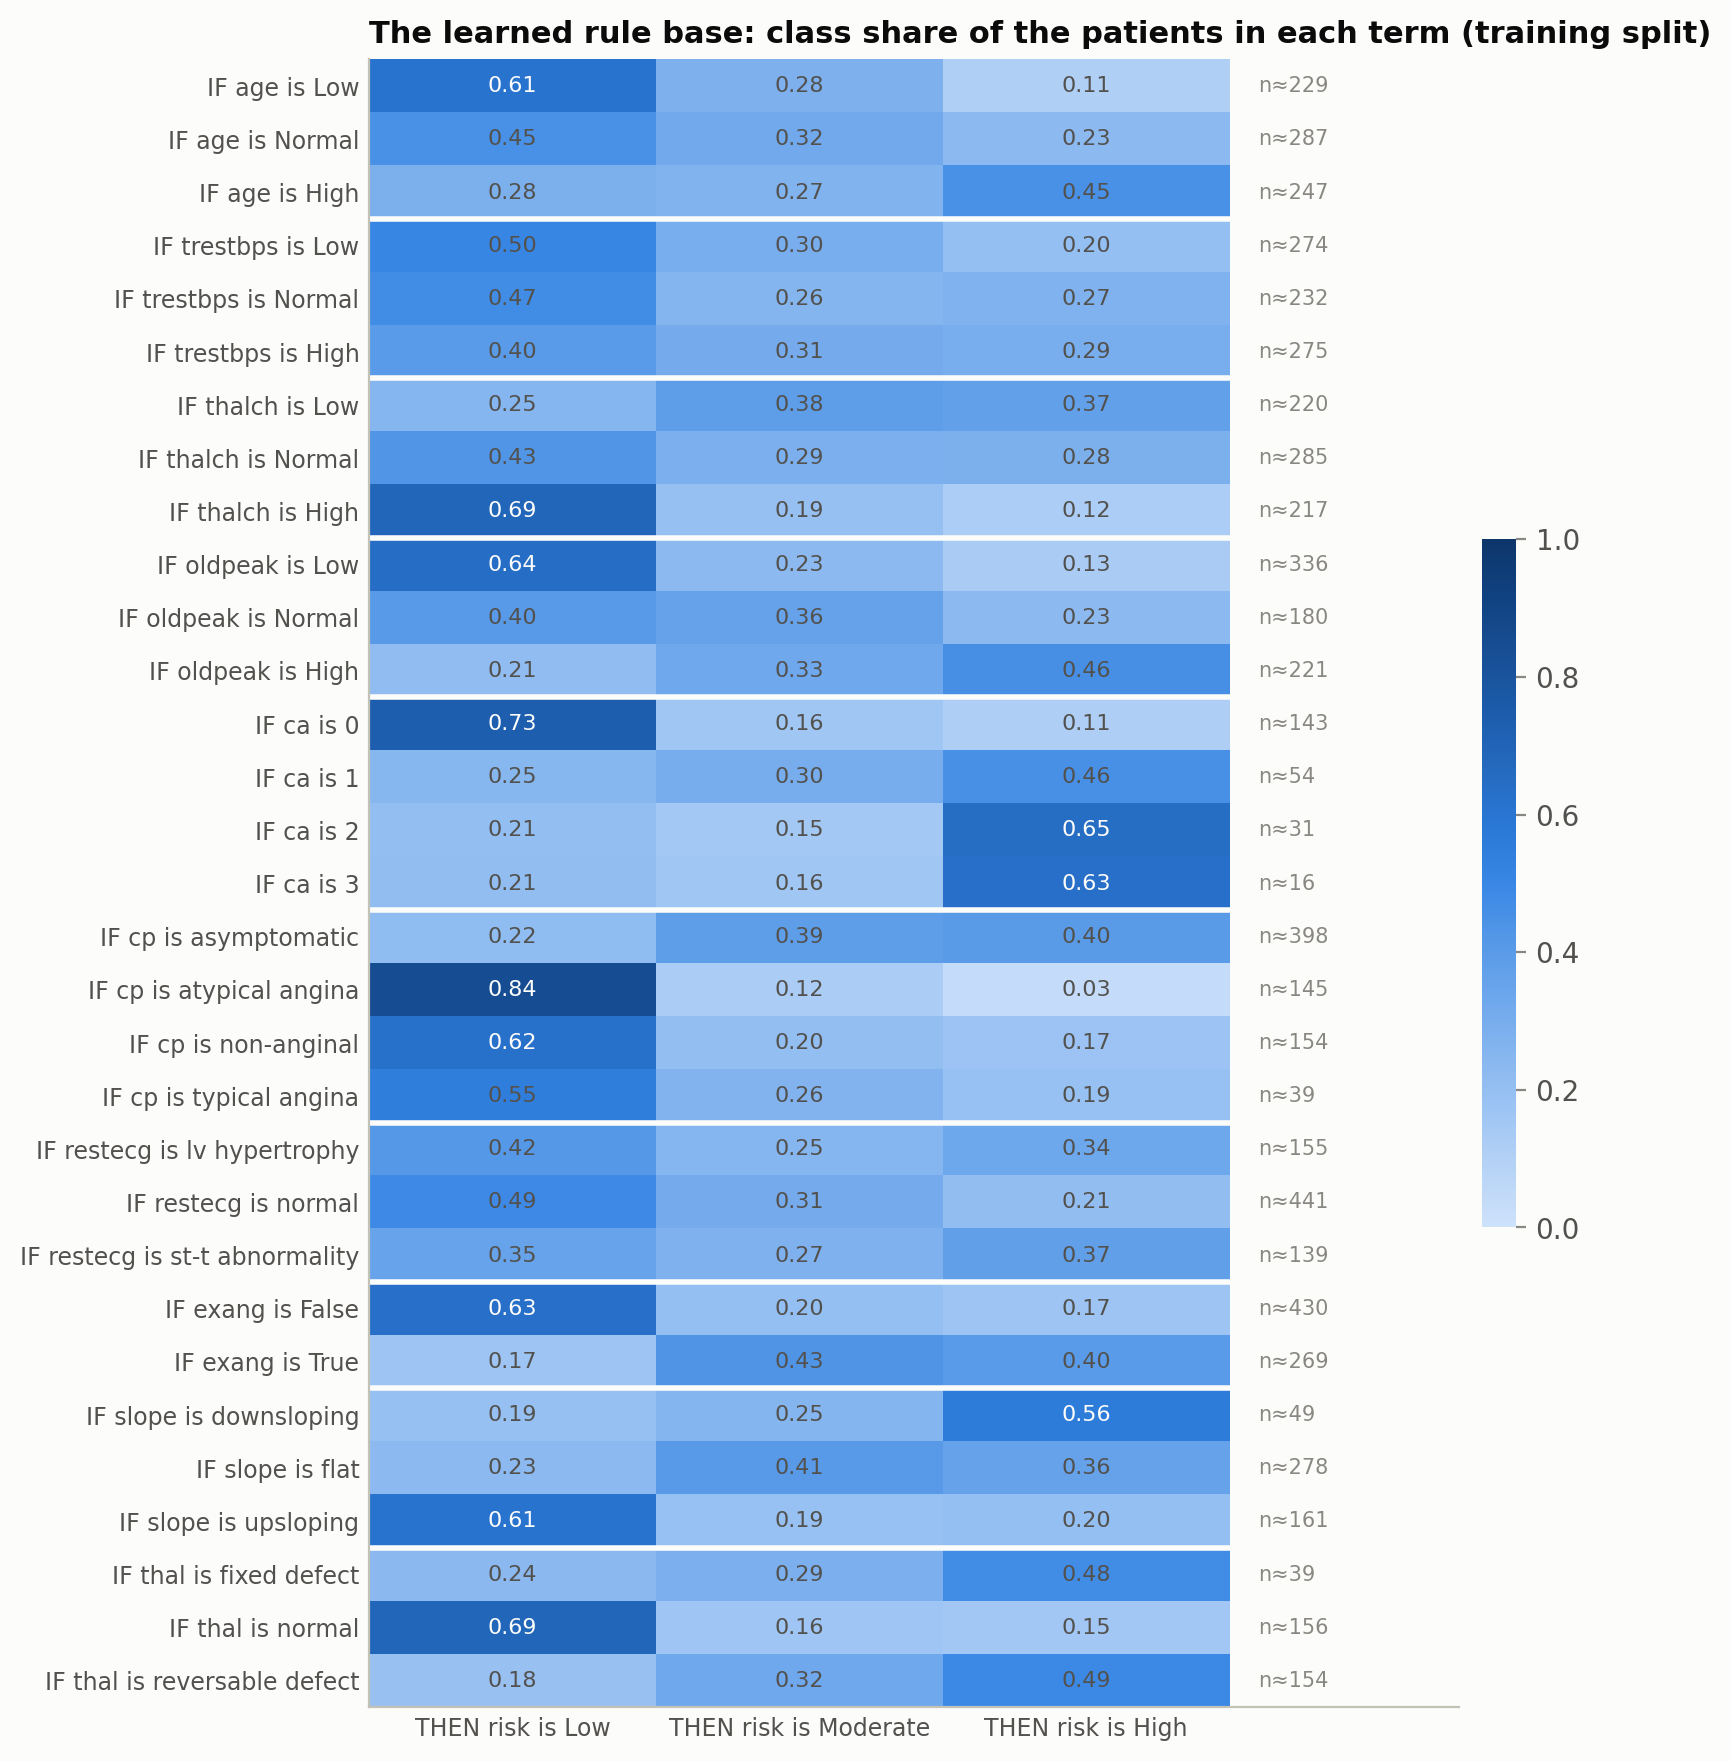

In [3]:
Image("../figures/05_rules.png", width=760)

The rule base is readable and clinically sensible: atypical angina, a normal thalassemia test, a high maximum heart rate, no exercise-induced angina and no ST depression all point to *Low*; two or more coloured vessels, a downsloping ST segment, a reversible defect and high ST depression point to *High*. Resting blood pressure barely separates the classes, which is why it gets a weight of zero below.

## 2. Attribute weights

In [4]:
pd.read_csv(R + "05_attribute_weights.csv", index_col=0).round(3)

,inner_macro_f1,n_available,weight
attribute,,,
age,0.381,736,0.091
trestbps,0.209,694,0.002
thalch,0.390,699,0.096
oldpeak,0.438,693,0.121
ca,0.480,244,0.143
cp,0.482,736,0.144
restecg,0.284,735,0.041
exang,0.407,699,0.105
slope,0.461,488,0.133


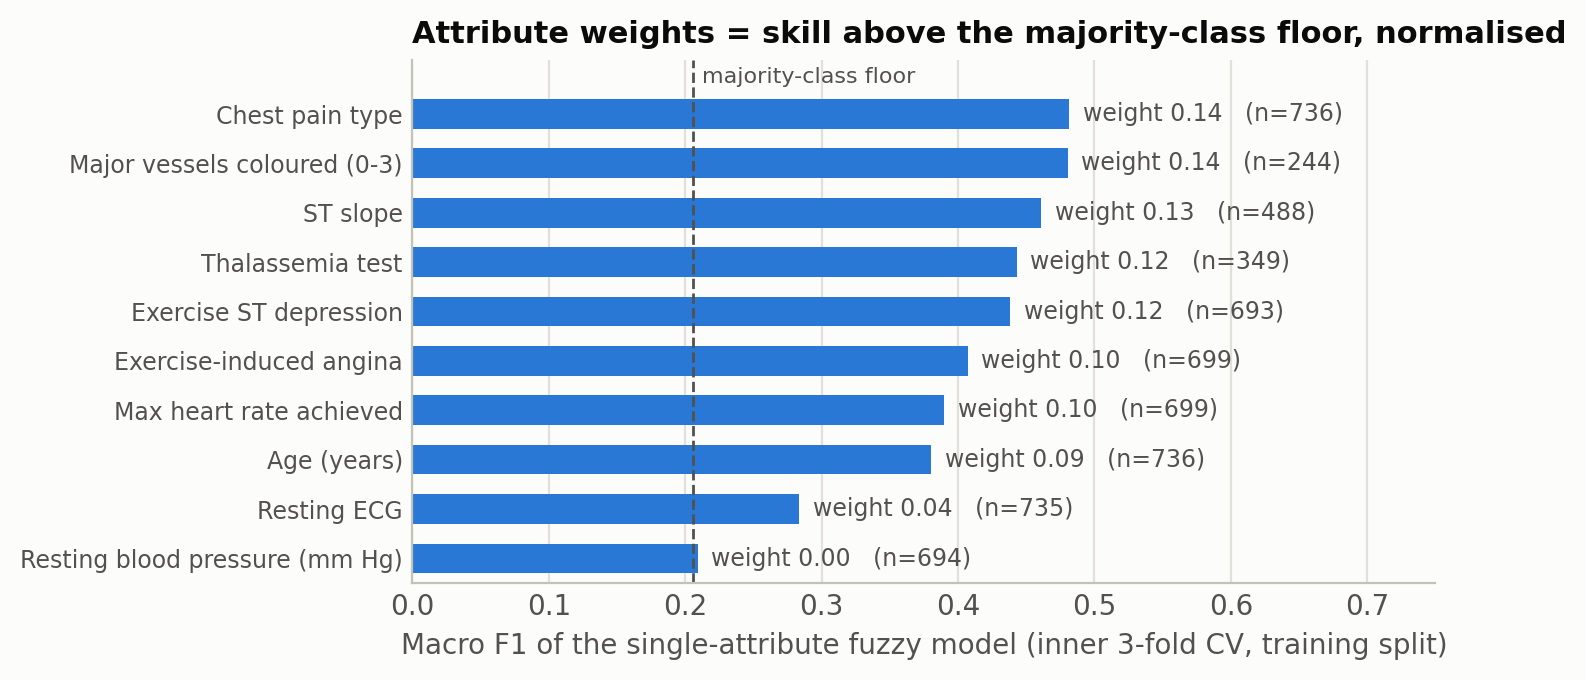

In [5]:
Image("../figures/05_attribute_weights.png", width=680)

`n_available` is how many training patients had the attribute measured in the inner CV. `ca` has the joint-highest skill but on only 244 patients; for the other 492 it simply does not take part.

## 3. Evaluation with the phase 2 protocol

In [6]:
cv = pd.read_csv(R + "05_fuzzy_cv.csv", index_col=0)
base = pd.read_csv(R + "02_baselines_cv.csv", index_col=0)
pd.concat([base, cv])[["macro_f1_mean", "macro_f1_std", "accuracy_mean", "weighted_f1_mean"]].round(3)

,macro_f1_mean,macro_f1_std,accuracy_mean,weighted_f1_mean
majority_class,0.206,0.001,0.447,0.276
logistic_regression,0.619,0.045,0.651,0.644
random_forest,0.629,0.048,0.664,0.654
mlp,0.605,0.040,0.639,0.632
hybrid_fuzzy,0.581,0.027,0.603,0.610
hybrid_fuzzy_argmax,0.541,0.039,0.615,0.570


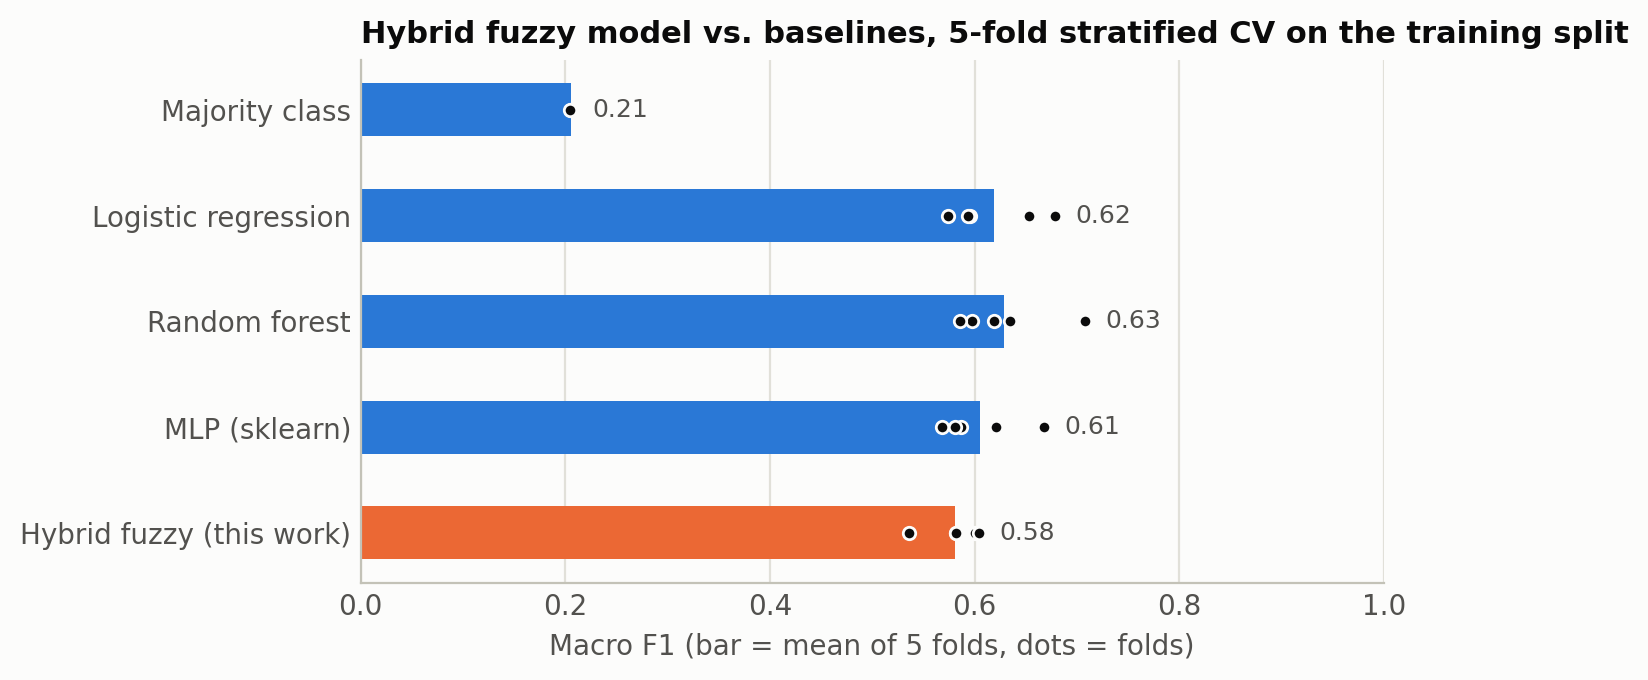

In [7]:
Image("../figures/05_fuzzy_vs_baselines.png", width=680)

In [8]:
test = pd.concat([pd.read_csv(R + "02_baselines_test.csv", index_col=0), pd.read_csv(R + "05_fuzzy_test.csv", index_col=0)])
test.round(3)

,accuracy,macro_f1,weighted_f1,f1_Low,f1_Moderate,f1_High
model,,,,,,
majority_class,0.446,0.206,0.275,0.617,0.000,0.000
logistic_regression,0.647,0.613,0.644,0.798,0.514,0.526
random_forest,0.652,0.618,0.644,0.777,0.511,0.566
mlp,0.609,0.562,0.595,0.770,0.382,0.533
hybrid_fuzzy,0.516,0.496,0.532,0.716,0.347,0.424
hybrid_fuzzy_argmax,0.587,0.512,0.547,0.725,0.371,0.440


**Reading the numbers honestly.**

- Under 5-fold CV the hybrid fuzzy model reaches a macro F1 of 0.58 ± 0.03, against 0.61 to 0.63 for the three baselines: about one fold's standard deviation below the baselines and well above the 0.21 majority-class floor.
- On the held-out test split it drops to 0.50 (accuracy 0.52), a larger drop than the baselines show (0.61 to 0.62). With 184 test patients the standard error of macro F1 is about 0.04, so this is a real but not dramatic gap.
- The `hybrid_fuzzy_argmax` row is a diagnostic: it skips the output sets and the centroid, and takes the largest combined class score instead. It is *worse* on macro F1 in CV (0.54 vs 0.58) and only marginally better on the test split (0.51 vs 0.50), so the patent's defuzzification path with learned cut-points is not what costs accuracy. The fuzzy model's remaining gap to the baselines comes from the model itself: single-attribute rules cannot represent interactions between attributes, and no imputation means a VA or Swiss patient is scored on fewer attributes.

Where the three classes land on the risk axis, and the learned cut-points:

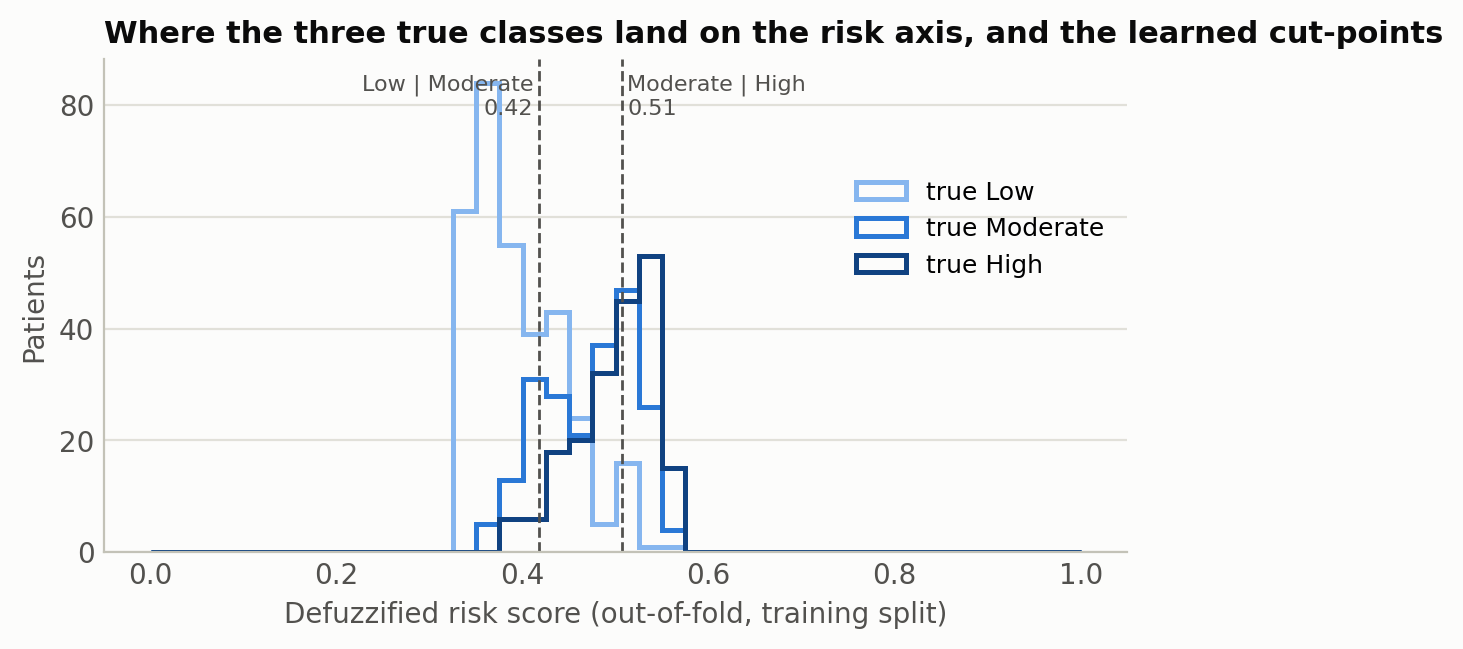

In [9]:
Image("../figures/05_risk_score_distribution.png", width=680)

The risk axis is compressed (nearly all patients between 0.33 and 0.57) because the combined scores are averages of smoothed class shares and rarely approach 0 or 1; the cut-points adapt to that. *Moderate* occupies a band only 0.09 wide, which is the ordinal-middle-class problem seen in every model in this project.

## 4. Per-hospital diagnostic

In [10]:
site = pd.read_csv(R + "05_per_site.csv")
site[site.model == "hybrid_fuzzy"].set_index("site").drop(columns="model").round(3)

,n,accuracy,macro_f1,weighted_f1
site,,,,
Cleveland,242,0.603,0.561,0.640
Hungary,240,0.742,0.739,0.780
Switzerland,97,0.433,0.390,0.441
VA Long Beach,157,0.497,0.471,0.501


Same shape as for the baselines: Hungary easiest, Switzerland hardest. Note that the fuzzy model matches the baselines on Switzerland (0.43 accuracy) *without* seeing any imputed cholesterol or vessel count: Swiss patients are scored on the attributes that were actually measured.

## 5. Explaining one patient

This is what the method is for. `explain` returns, for one patient, every fired term with its membership, each attribute's class scores, its effective weight after renormalisation, the combined scores, the aggregated output shape, the centroid and the decision.

In [11]:
df = data.load_dataset()
train, test = data.make_split(df)
X_train, y_train = data.split_xy(train)
X_test, y_test = data.split_xy(test)
model = HybridFuzzyClassifier(attributes=attrs).fit(X_train, y_train)

ex_meta = json.load(open(R + "05_explanations.json"))
i = ex_meta["complete"]["meta"]["test_index"]
row = X_test.iloc[[i]]
ex = model.explain(row)
print(f"patient id {test['id'].iloc[i]}, {test[config.SITE_COL].iloc[i]}; true {y_test.iloc[i]}, predicted {ex['predicted']}, "
      f"risk {ex['risk_score']:.3f}, cut-points {tuple(round(c, 3) for c in ex['cutpoints'])}")
pd.DataFrame([{"attribute": r["attribute"], "value": r["value"], "fired": r["fired_terms"],
               "weight": round(r["effective_weight"], 3), **(r["contribution"] or {})} for r in ex["attributes"]])

patient id 192, Cleveland; true High, predicted High, risk 0.550, cut-points (0.417, 0.506)


,attribute,value,fired,weight,Low,Moderate,High
0,age,51,"{'Low': 0.160587997990194, 'Normal': 0.8571428...",0.091,0.0433,0.0283,0.0196
1,trestbps,140.0,"{'Low': 0.0009815604591000046, 'Normal': 0.454...",0.002,0.0007,0.0005,0.0005
2,thalch,122.0,"{'Low': 0.5333333333333333, 'Normal': 0.466666...",0.096,0.0319,0.0326,0.0316
3,oldpeak,4.2,"{'Low': 2.5756993106069683e-72, 'Normal': 1.62...",0.121,0.0257,0.0398,0.0557
4,ca,3.0,{'3': 1.0},0.143,0.0302,0.0226,0.0906
5,cp,asymptomatic,{'asymptomatic': 1.0},0.144,0.0312,0.0557,0.0571
6,restecg,normal,{'normal': 1.0},0.041,0.0197,0.0124,0.0084
7,exang,True,{'True': 1.0},0.105,0.0178,0.0452,0.0421
8,slope,flat,{'flat': 1.0},0.133,0.0308,0.0540,0.0483
9,thal,reversable defect,{'reversable defect': 1.0},0.124,0.0229,0.0402,0.0607


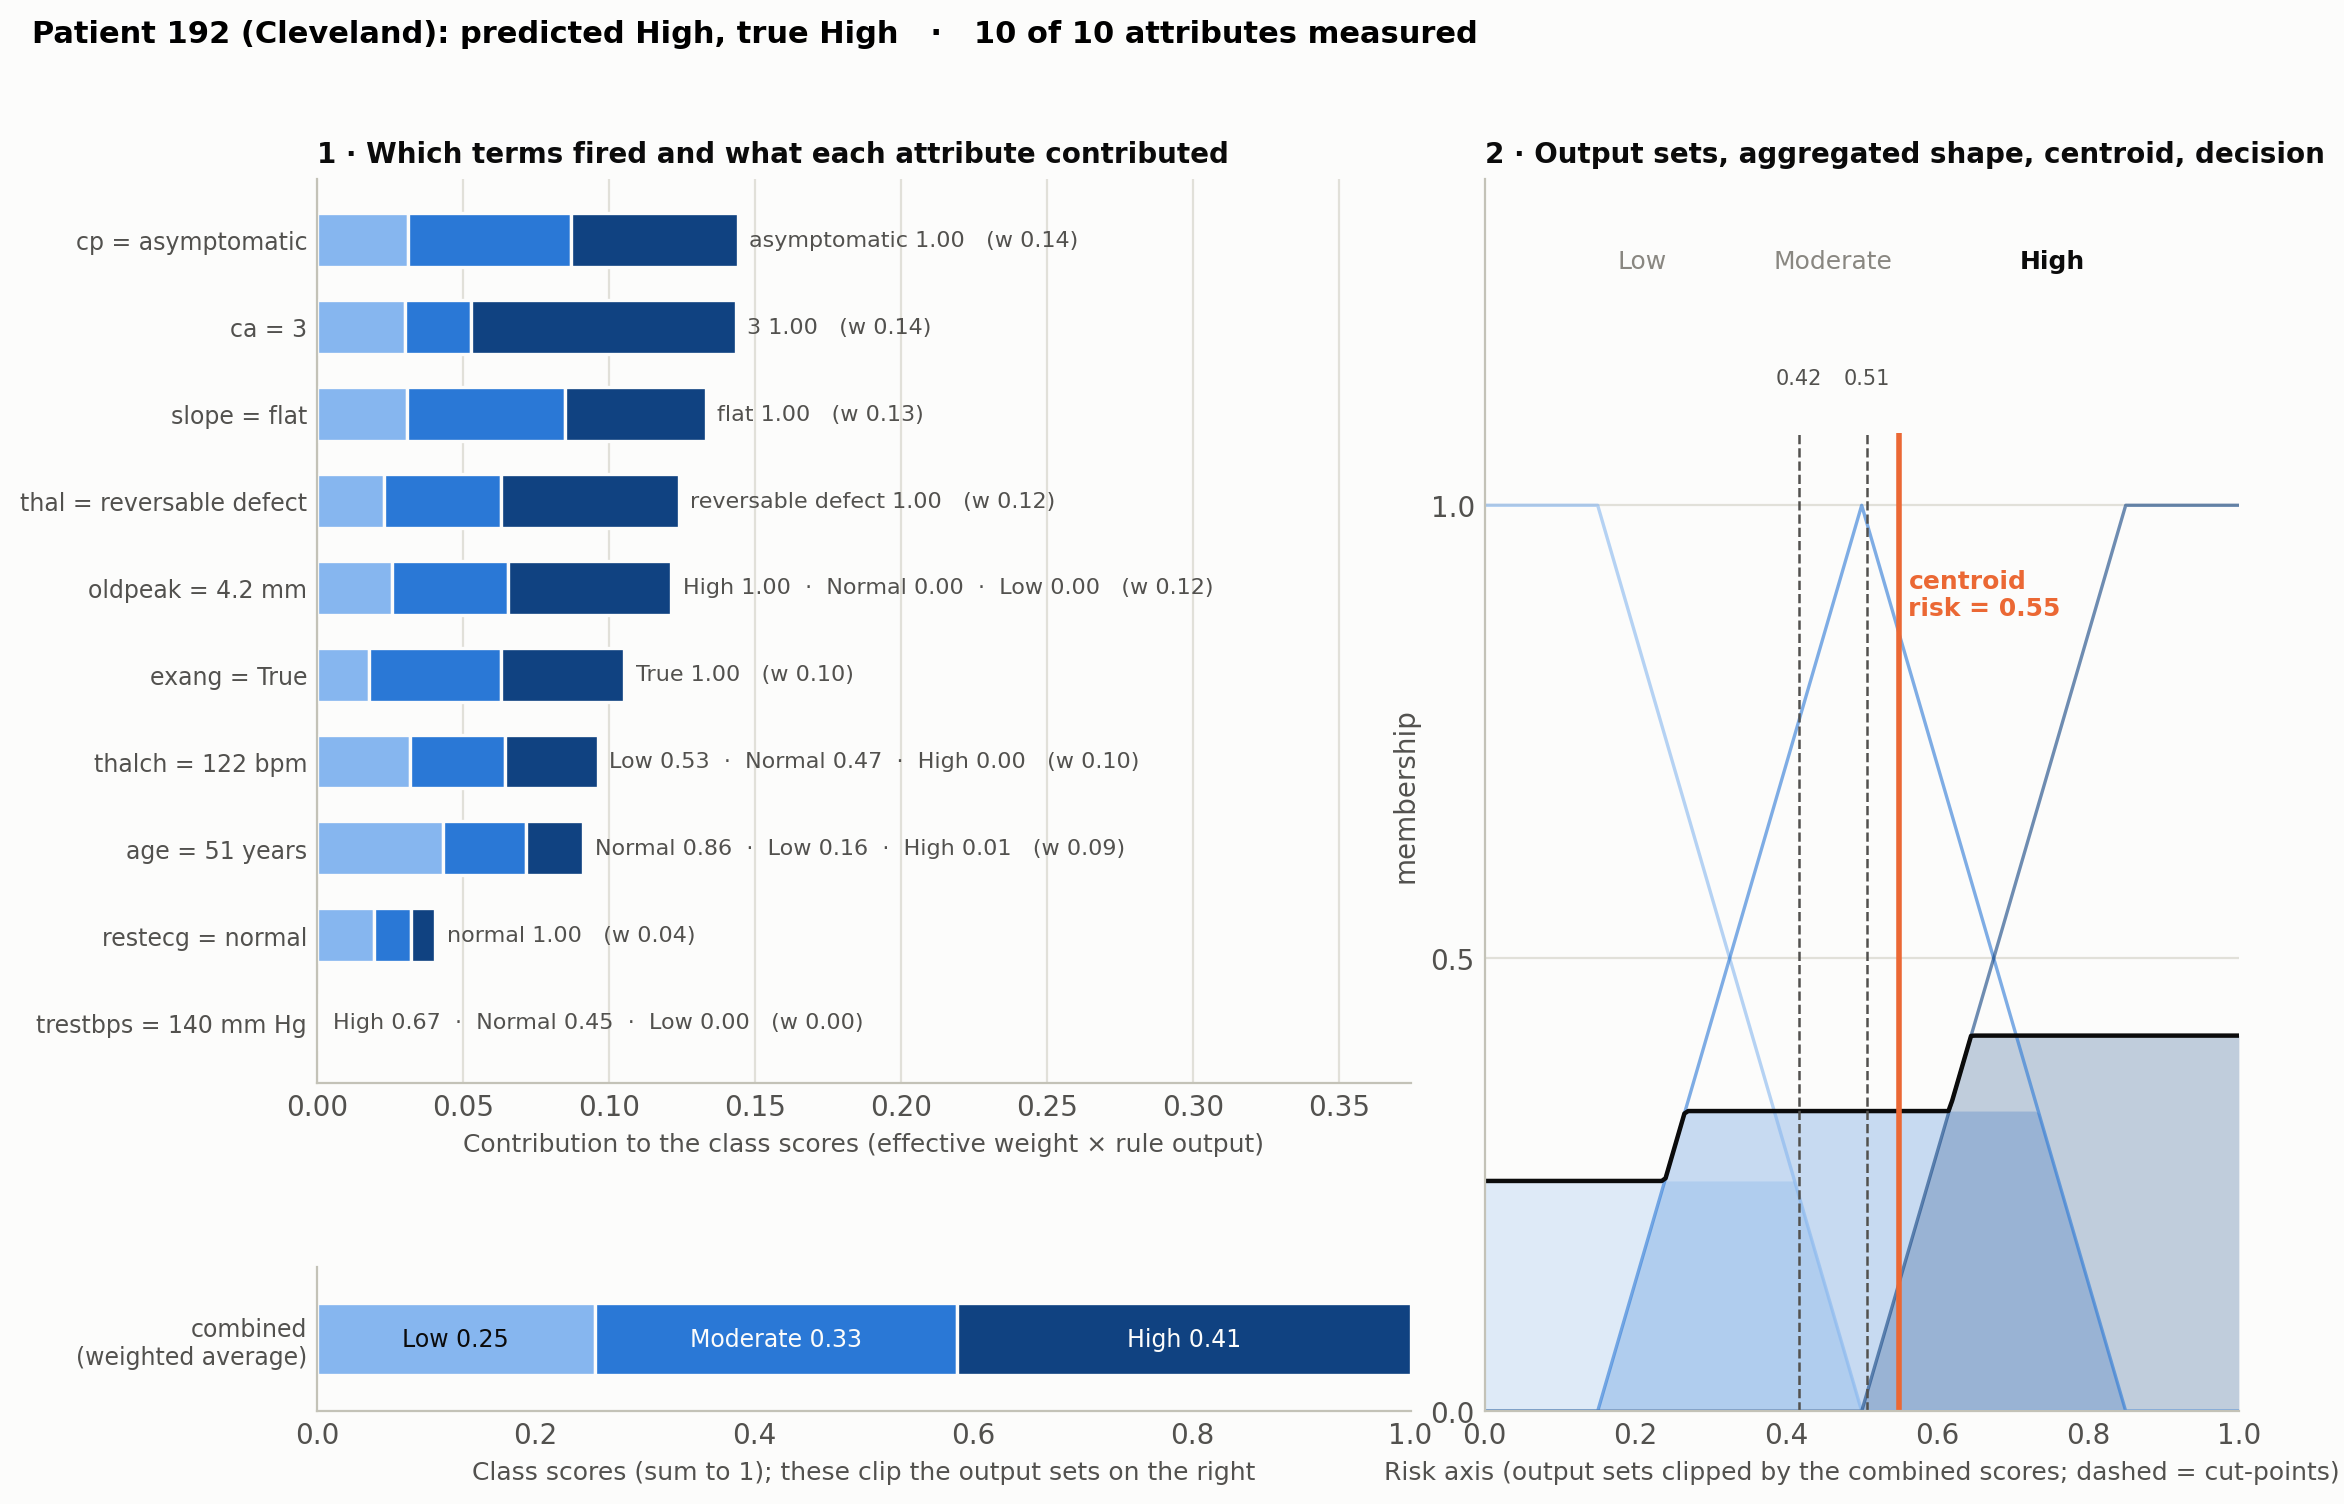

In [12]:
Image("../figures/05_explain_patient_complete.png", width=980)

Read left to right: every measured attribute fires one or two terms (a 51-year-old is *Normal* 0.86 and *Low* 0.16 on age); each fired rule contributes its class shares scaled by the attribute's weight; the stacked contributions add up to the combined scores (Low 0.25 / Moderate 0.33 / High 0.41); those clip the three output sets; the centroid of the aggregated shape is 0.55, which lies above the Moderate | High cut-point, so the prediction is *High*.

The same for a patient whose fluoroscopy and thalassemia test were never done:

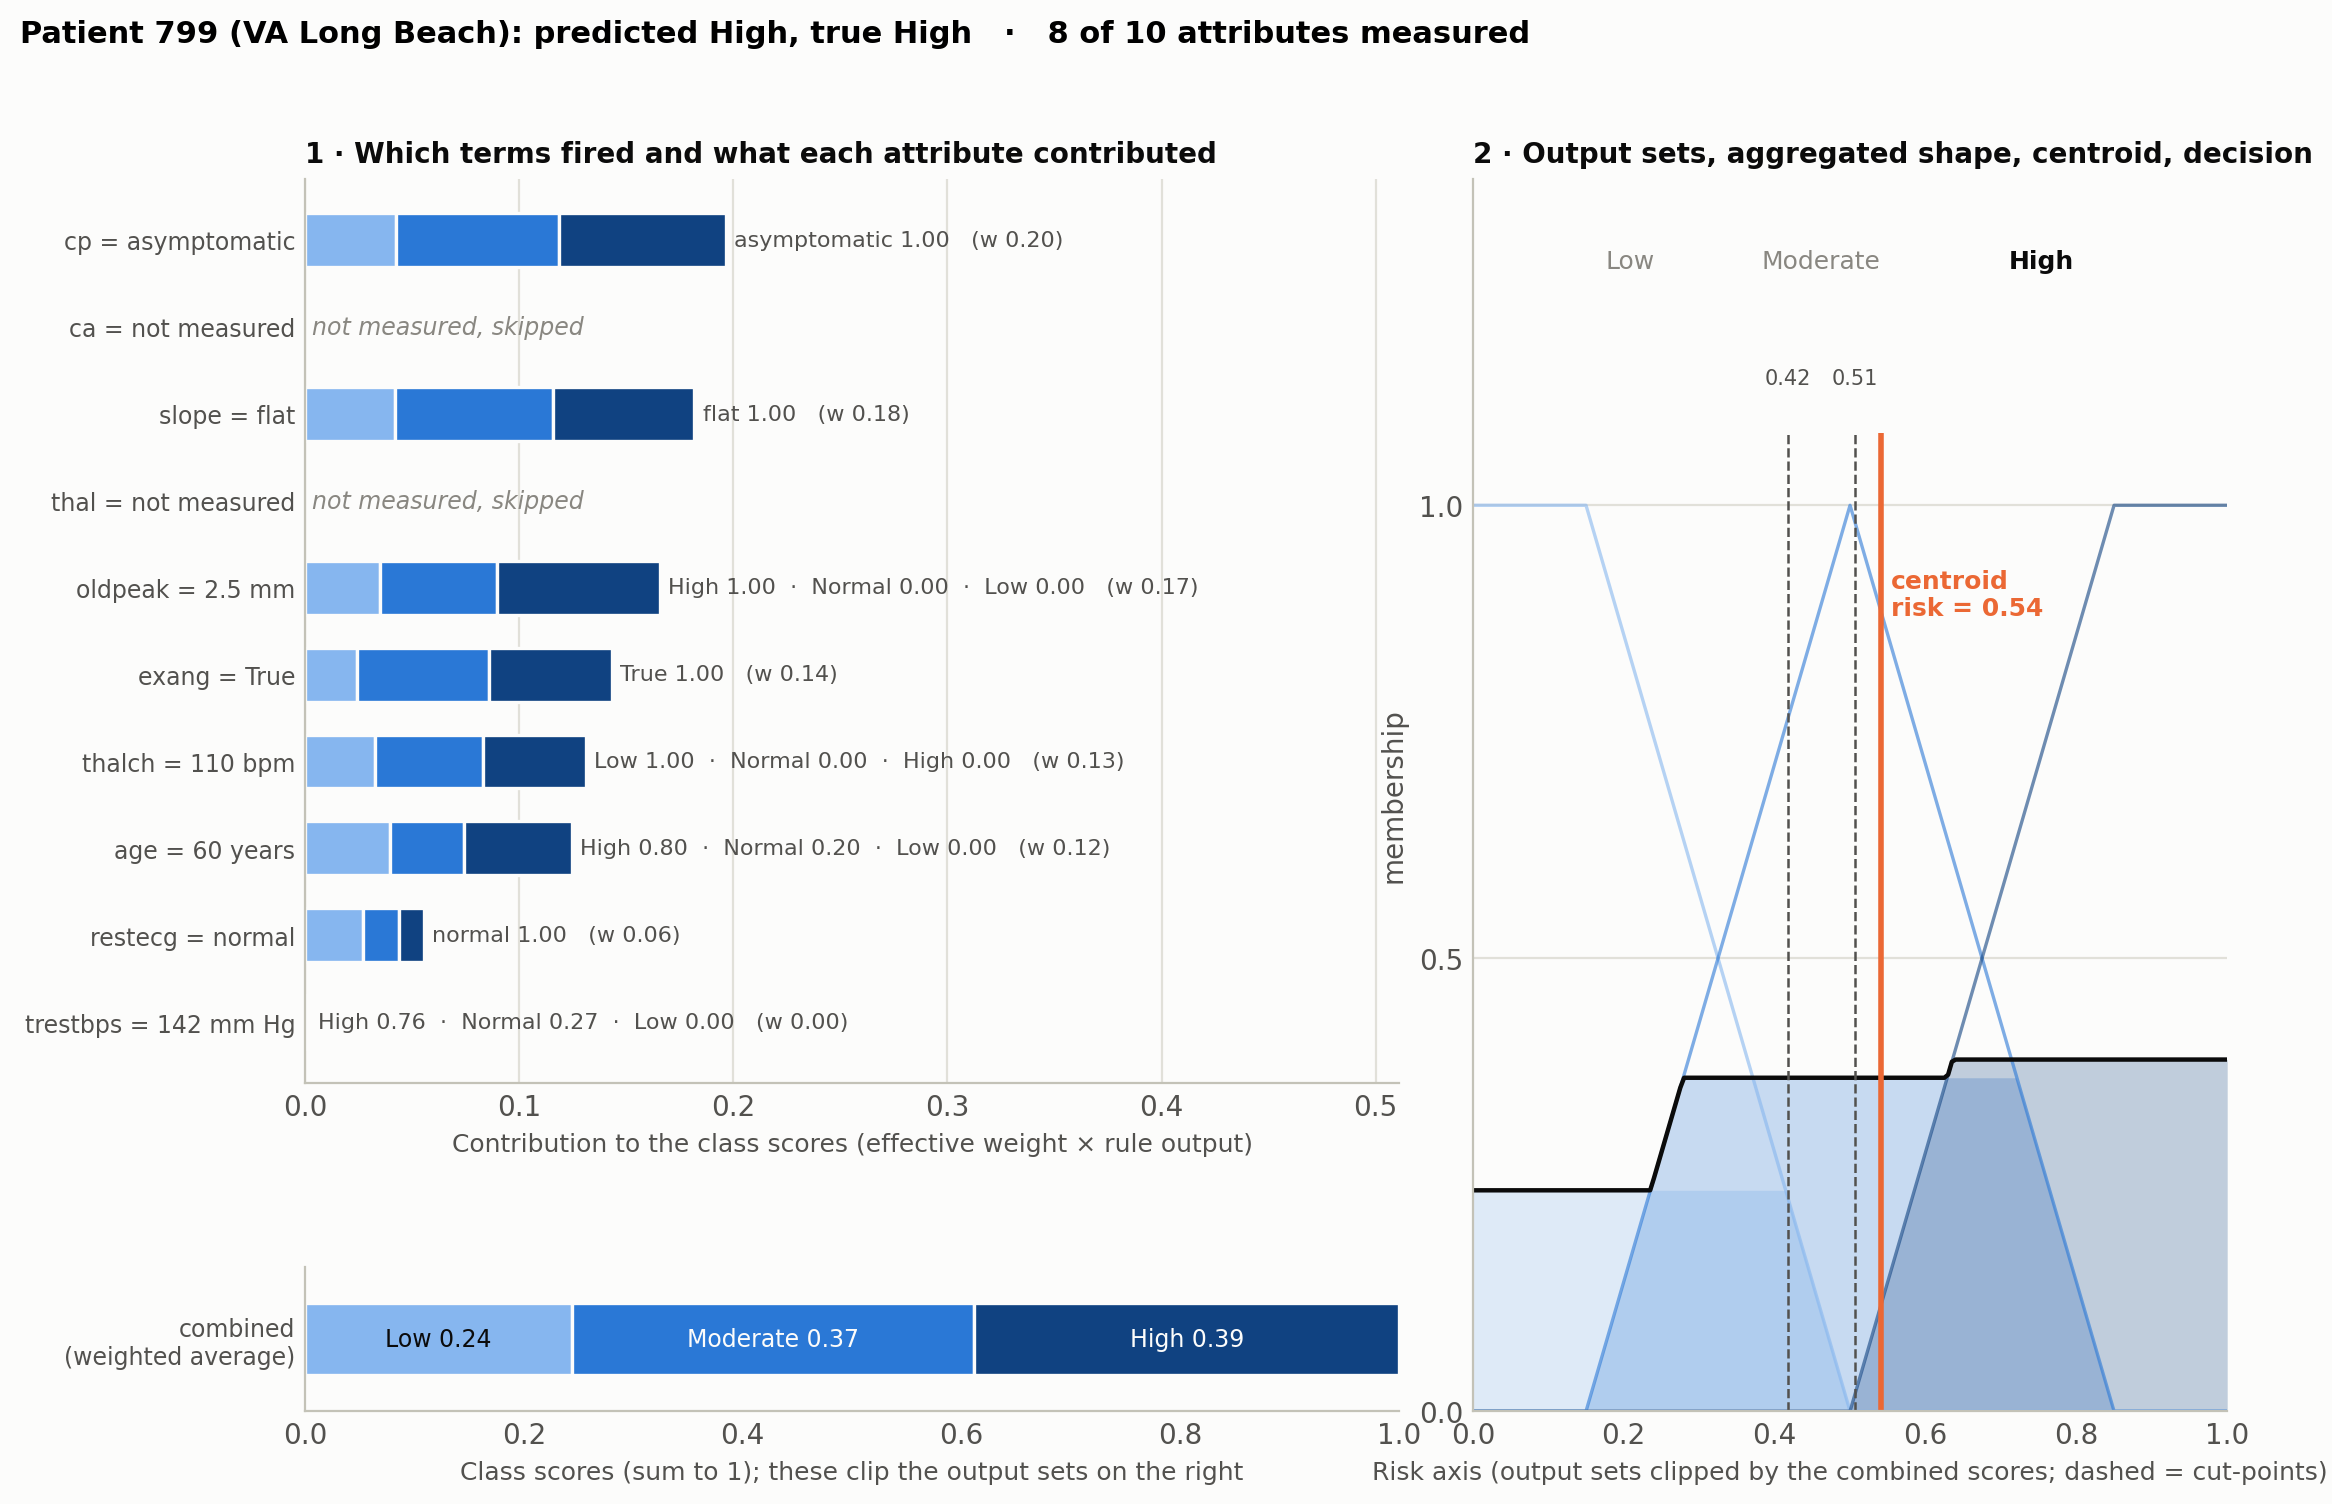

In [13]:
Image("../figures/05_explain_patient_missing.png", width=980)

`ca` and `thal` are marked *not measured, skipped*; the eight measured attributes carry the full weight (chest pain type rises from 0.14 to 0.20). Nothing was imputed and nothing about the source hospital leaked in.

## What was not built

A compact Wang–Mendel rule base with two- or three-antecedent rules was considered as a comparison. On ten attributes with three to four terms each, even the pairwise version produces several hundred rules, which is not readable; it is left in the README backlog.

## Outputs

`results/05_*`, `figures/05_*.png`. **Next phase:** the final evaluation and explainability write-up (phase 6).